In [2]:
import pandas as pd
import json 
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
RESULT_DIR = "/data/Kushal/UniversalRetrieval_data/"

# Multiple Dataset

In [3]:
representative_order = [
    #Popular Representation
    'pipe_serialized',
    'token_serialized',
    'space_serialized',
    # Data Representation
    'csv',
    'tsv',
    'html',
    'markdown',
    'latex',
    'dict',
    'json',
    'xml',
    # Structural Transformations 
    'shuffled_rows',
    'shuffled_cols',
    'transpose',
    #Schema Definition Types
    'mschema',
    'macschema',
    'ddl',
    #Centroid
    "centroid_popular",
    "centroid_data",
    "centroid_schema",
    "centroid_structural",
     "centroid_all",
]
category = {"Popular Representation": ['pipe_serialized',    'token_serialized', 'space_serialized',"centroid_popular"],
    "Data Representation" : [
            'csv',
            'tsv',
            'html',
            'markdown',
            'latex',
            'dict',
            'json',
            'xml',
            'centroid_data'],
    "Structural Transformations": ['shuffled_rows',
        'shuffled_cols',
        'transpose',
        'centroid_structural'],
    "Schema Definition Types" :['mschema',
    'macschema',
    'ddl',
    'centroid_schema'],
    "All" :['centroid_all'],
}
category_wo_centroid = {"Popular Representation": ['pipe_serialized',    'token_serialized', 'space_serialized'],
    "Data Representation" : [
            'csv',
            'tsv',
            'html',
            'markdown',
            'latex',
            'dict',
            'json',
            'xml',
            ],
    "Structural Transformations": ['shuffled_rows',
        'shuffled_cols',
        'transpose'],
    "Schema Definition Types" :['mschema',
    'macschema',
    'ddl'],
}

In [4]:
df_list = []

representative_wo_order = [
    'pipe_serialized', 'token_serialized', 'space_serialized',
    'csv', 'tsv', 'html', 'markdown', 'latex', 'dict', 'json', 'xml',
    'shuffled_rows', 'shuffled_cols', 'transpose',
    'mschema', 'macschema', 'ddl', "centroid_all"
]

for adapter_type in ["base", "adapter", "adapter_subset"]:
    for dataset in ["WTQ", "WIKISQL", "NQ"]:
        for model in ["splade","qwen0.6B", "qwen4B", "miniLM", "mdbr", "bge", "mpnet", "reasonir"]:
            model_train_date = "2026-09-17" if model in ["bge","splade","miniLM"] and adapter_type in ["adapter","adapter_subset"] else "2026-09-12"
            df_model = None

            for representative in representative_wo_order:
                if adapter_type == "base":
                    fpath = f"{RESULT_DIR}/retrieval_all/{model}_results_rank/{dataset}/chunked_{representative}_gold_rank_per_question.csv"
                else:
                    fpath = f"{RESULT_DIR}/retrieval_all/{model}_results_rank_with_{adapter_type}/{model_train_date}/{dataset}/chunked_{representative}_gold_rank_per_question.csv"

                if not Path(fpath).exists():
                    continue

                df_rep = pd.read_csv(fpath)[["model", "dataset", "question_id", "rank", "hit@1"]]
                df_rep = df_rep.rename(columns={"rank": representative, "hit@1": f"{representative}_hit@1"})

                if df_model is None:
                    df_model = df_rep
                else:
                    df_model = df_model.merge(df_rep, on=["model", "dataset", "question_id"], how="inner", validate="one_to_one")

            if df_model is None:
                print(f"[warning] No files found for {adapter_type} | {dataset} | {model}")
                continue

            df_model["adapter_type"] = adapter_type
            df_list.append(df_model)

df = pd.concat(df_list, ignore_index=True).drop_duplicates()

KeyboardInterrupt: 

# Comparison

In [ ]:
id_cols = ["model", "dataset", "question_id", "adapter_type"]
rank_cols = [c for c in df.columns if c not in id_cols and not c.endswith("_hit@1")]
hit_cols = [f"{c}_hit@1" for c in rank_cols if f"{c}_hit@1" in df.columns]

rank_long = df.melt(id_vars=id_cols, value_vars=rank_cols, var_name="representation", value_name="rank")
hit_long = df.melt(id_vars=id_cols, value_vars=hit_cols, var_name="representation_hit", value_name="hit1")
hit_long["representation"] = hit_long["representation_hit"].str.replace("_hit@1", "", regex=False)
hit_long = hit_long.drop(columns="representation_hit")

long_df = rank_long.merge(hit_long, on=["model", "dataset", "question_id", "adapter_type", "representation"], how="inner", validate="one_to_one")

base_df = long_df[long_df["adapter_type"] == "base"].rename(columns={"rank": "base_rank", "hit1": "base_hit1"}).drop(columns="adapter_type")

cmp_list = []
for comp in ["adapter", "adapter_subset"]:
    adapt_sub = long_df[long_df["adapter_type"] == comp].rename(columns={"rank": "adapt_rank", "hit1": "adapt_hit1"}).drop(columns="adapter_type")
    cmp_sub = base_df.merge(adapt_sub, on=["model", "dataset", "question_id", "representation"], how="inner", validate="one_to_one")
    cmp_sub["compare_to"] = comp
    cmp_list.append(cmp_sub)

cmp = pd.concat(cmp_list, ignore_index=True)
cmp["delta_rank"] = cmp["base_rank"] - cmp["adapt_rank"]
cmp["log_delta_rank"] = np.log1p(cmp["base_rank"]) - np.log1p(cmp["adapt_rank"])
cmp["improved"] = cmp["adapt_rank"] < cmp["base_rank"]
cmp["worsened"] = cmp["adapt_rank"] > cmp["base_rank"]
cmp["same"] = cmp["adapt_rank"] == cmp["base_rank"]
cmp["delta_hit1"] = cmp["adapt_hit1"] - cmp["base_hit1"]

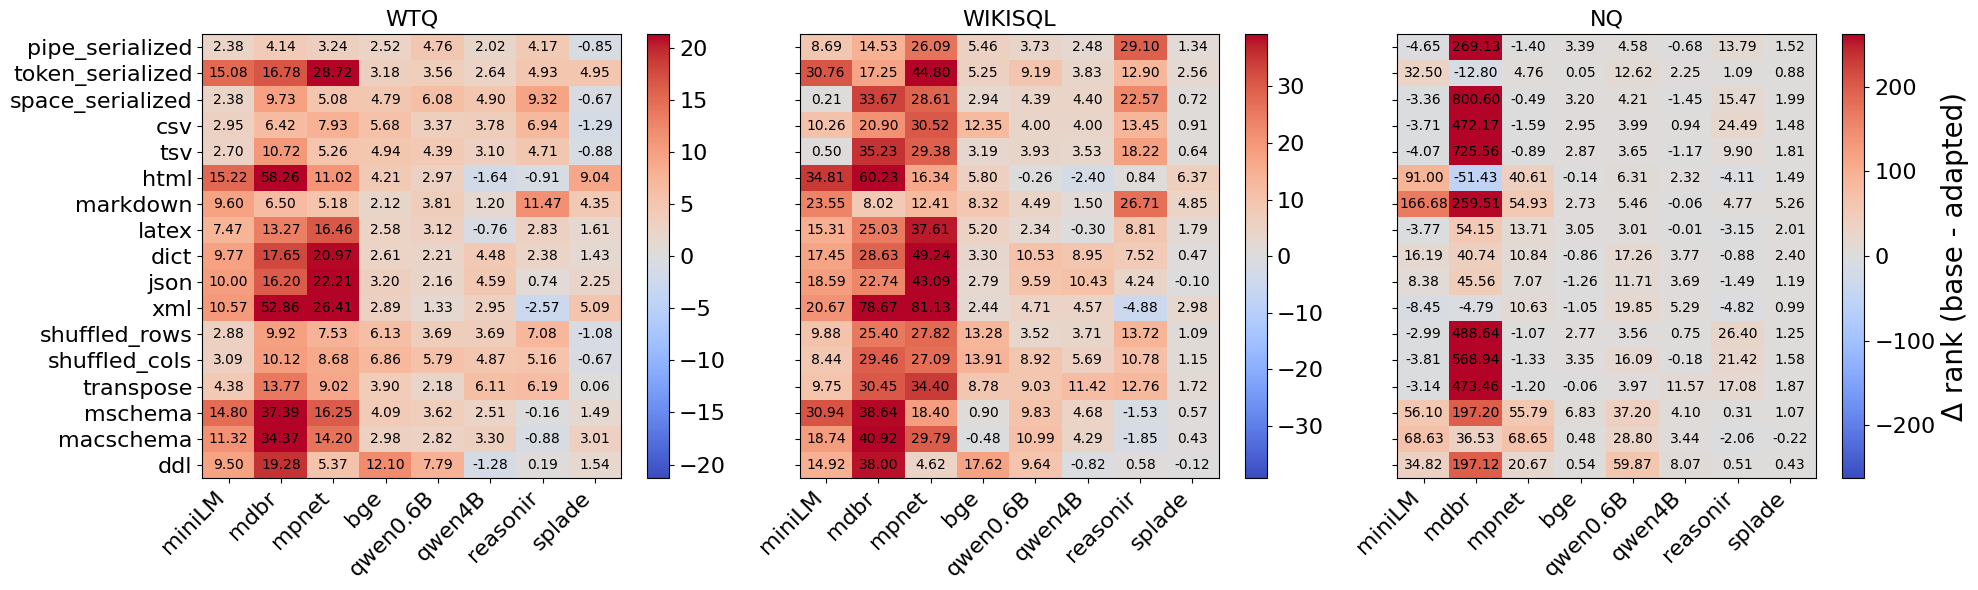

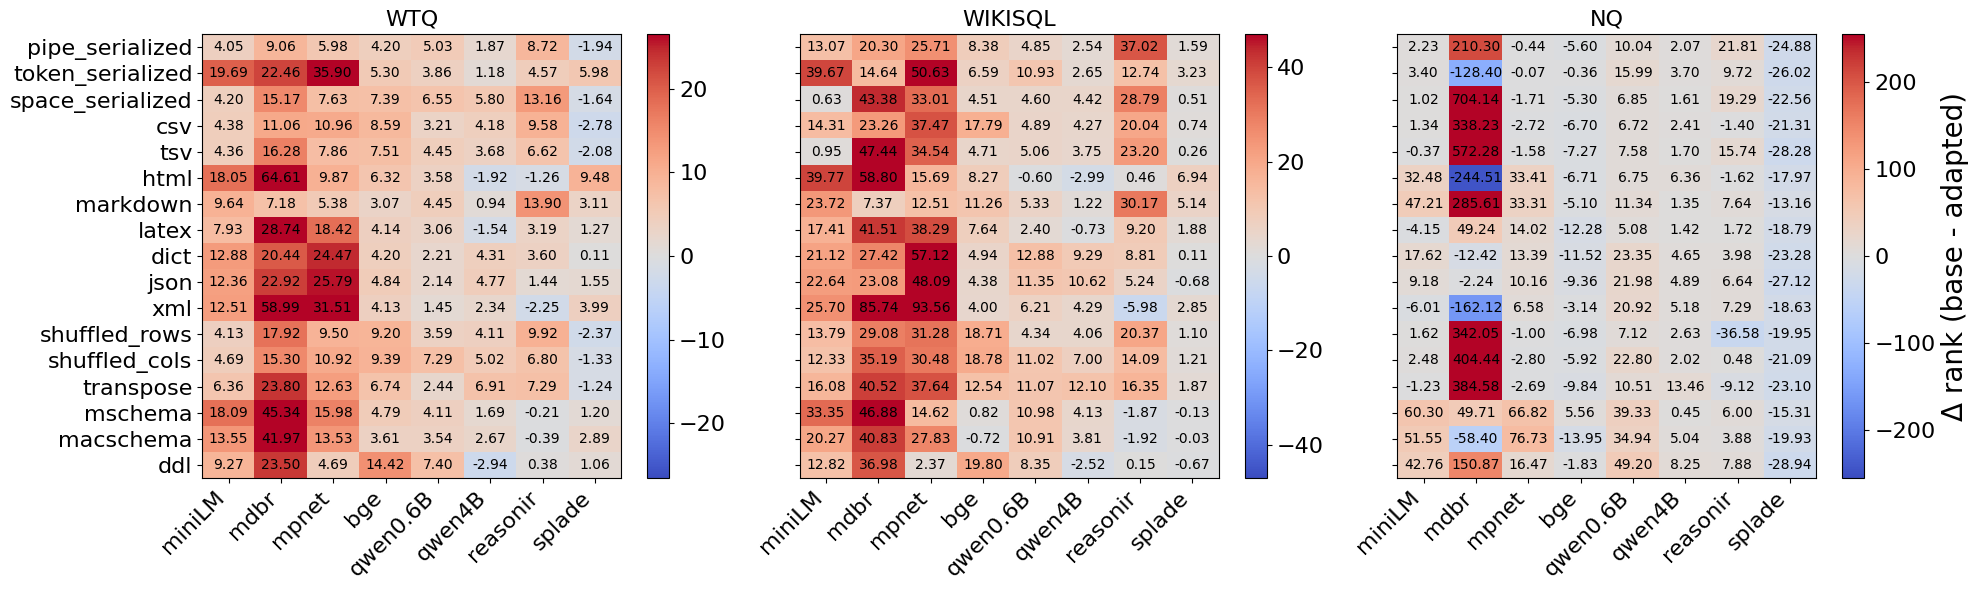

In [ ]:
representative_order = [
    "pipe_serialized", "token_serialized", "space_serialized",
    "csv", "tsv", "html", "markdown", "latex", "dict", "json", "xml",
    "shuffled_rows", "shuffled_cols", "transpose",
    "mschema", "macschema", "ddl"
]

model_order = ["splade", "qwen0.6B", "qwen4B", "miniLM", "mdbr", "bge", "mpnet", "reasonir"]
model_order = [ "miniLM", "mdbr", "mpnet","bge",  "qwen0.6B", "qwen4B", "reasonir","splade"]
use_log = False#True 


def draw_heatmap(ax, pivot, title, cmap, vmin=None, vmax=None, fmt="{:.2f}", show_yticks=True):
    im = ax.imshow(pivot.values, aspect="auto", cmap=cmap, vmin=vmin, vmax=vmax)
    ax.set_xticks(range(len(pivot.columns)))
    ax.set_xticklabels(pivot.columns, rotation=45, ha="right", fontsize=16)
    ax.set_yticks(range(len(pivot.index)))
    ax.set_yticklabels(pivot.index if show_yticks else [], fontsize=16)
    ax.set_title(title, fontsize=16)
    for i in range(pivot.shape[0]):
        for j in range(pivot.shape[1]):
            val = pivot.iloc[i, j]
            if pd.notna(val):
                ax.text(j, i, fmt.format(val), ha="center", va="center", fontsize=10)
    return im

datasets = sorted(cmp["dataset"].unique(), reverse=True)

for comp in ["adapter", "adapter_subset"]:
    fig, axes = plt.subplots(1, len(datasets), figsize=(20, 6))
    axes = np.atleast_1d(axes)

    for idx, dataset in enumerate(datasets):
        sub = cmp[(cmp["compare_to"] == comp) & (cmp["dataset"] == dataset)]

        delta_pivot = sub.groupby(["representation", "model"])["log_delta_rank" if use_log else "delta_rank"].mean().unstack("model")
        ordered_index = [r for r in representative_order if r in delta_pivot.index]
        ordered_cols = [m for m in model_order if m in delta_pivot.columns]
        delta_pivot = delta_pivot.reindex(index=ordered_index, columns=ordered_cols)

        v = np.nanpercentile(np.abs(delta_pivot.values), 95)
        im = draw_heatmap(axes[idx], delta_pivot, dataset, "coolwarm", -v, v, "{:.2f}", show_yticks=idx == 0)

        cbar = fig.colorbar(im, ax=axes[idx])
        cbar.ax.tick_params(labelsize=16)
        if idx == len(datasets) - 1:
            cbar.set_label("Δ log-rank  (base - adapted)" if use_log else "Δ rank (base - adapted)", fontsize=20)

    plt.tight_layout()
    plt.show()